### Sampling distribution

A sampling distribution for the tips dataset, treating it as the population is plotted. Samples are drawn randomly to calculate sample statistics (mean for total_bill), and visualize their distribution:

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Load tips dataset
tips = sns.load_dataset('tips')
data = {
    'total_bill': tips.total_bill,
    'tip': tips.tip
}
df = pd.DataFrame(data)
df.head()

,total_bill,tip
0,16.99,1.01
1,10.34,1.66
2,21.01,3.50
3,23.68,3.31
4,24.59,3.61


In [3]:
# Treat 'total_bill' as the population
population = df['total_bill']

In [4]:
# Population mean and standard deviation
population_mean = np.mean(population)
population_std = np.std(population)

In [5]:
# Draw random samples and compute sample means
sample_size = 30        # Size of each sample
num_samples = 500       # Number of samples to draw

In [6]:
sample_means = []       # To store sample means

for n in range(num_samples):
    sample = np.random.choice(population, size=sample_size, replace=False)
    sample_means.append(np.mean(sample))

In [7]:
# Calculate the mean of sample means
sm = np.mean(sample_means)
sm

19.73834133333333

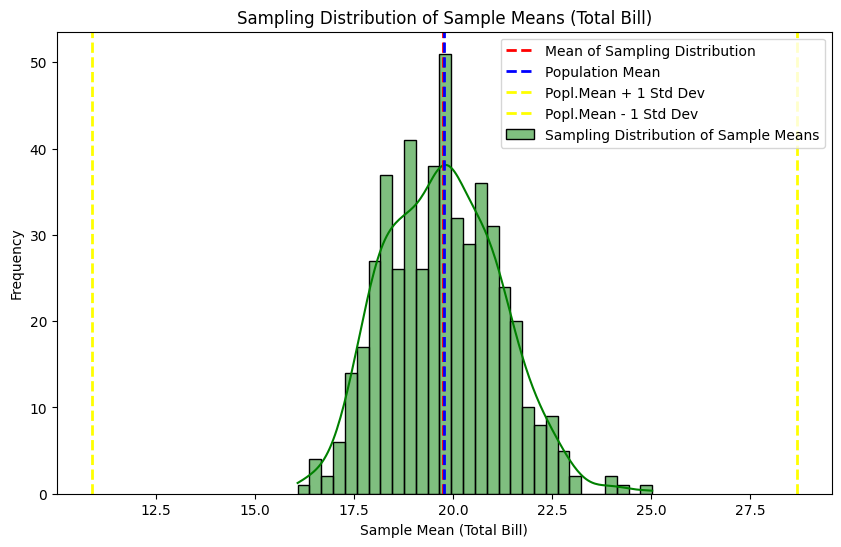

In [8]:
# Visualize the sampling distribution
plt.figure(figsize=(10, 6))

sns.histplot(sample_means, kde=True, color='green', bins=30, label='Sampling Distribution of Sample Means')

plt.axvline(sm, color='red', linestyle='--', linewidth=2, label='Mean of Sampling Distribution')
plt.axvline(population_mean, color='blue', linestyle='--', linewidth=2, label='Population Mean')
plt.axvline(population_mean + population_std, color='yellow', linestyle='--', linewidth=2, label='Popl.Mean + 1 Std Dev')
plt.axvline(population_mean - population_std, color='yellow', linestyle='--', linewidth=2, label='Popl.Mean - 1 Std Dev')

plt.title('Sampling Distribution of Sample Means (Total Bill)')
plt.xlabel('Sample Mean (Total Bill)')
plt.ylabel('Frequency')
plt.legend()

plt.show()

In [9]:
print('Mean of Sample Distribution:',sm)
print('Standard Error:',population_std/np.sqrt(sample_size))

Mean of Sample Distribution: 19.73834133333333
Standard Error: 1.6220165585726012


### Sampling distribution for proportions

Demonstrating the Sampling Distribution of a Sample Proportion and then comparing it with the theoretical Normal Distribution

In [2]:
# Check the gender column
tips['sex'].value_counts()

In [11]:
# Parameters
population = tips['sex'] == 'Male'     # Convert to binary: True = Male, False = Female
n_samples = 1000                       # Number of samples
sample_size = 30                       # Size of each sample

In [12]:
# Collect sample proportions

sample_proportions = []
for n in range(n_samples):
    sample = np.mean(np.random.choice(population, size=sample_size, replace=True))
    sample_proportions.append(sample)

In [17]:
print('Mean of Sample Distribution:',np.mean(sample_proportions))

Mean of Sample Distribution: 0.6447


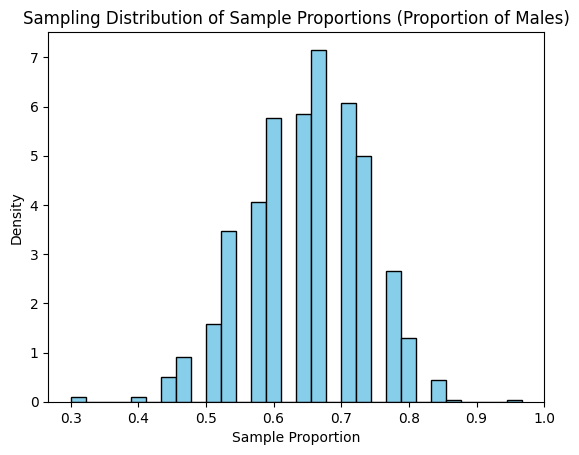

In [13]:
# Plot the sampling distribution
plt.hist(sample_proportions, bins=30, density=True, color='skyblue', edgecolor='black')
plt.title('Sampling Distribution of Sample Proportions (Proportion of Males)')
plt.xlabel('Sample Proportion')
plt.ylabel('Density')
plt.show()

##### Compare with Theoretical Distribution

In [14]:
from scipy.stats import norm

In [15]:
# Theoretical parameters
mean = 0.644
std_error = np.sqrt((mean * (1 - mean)) / sample_size)

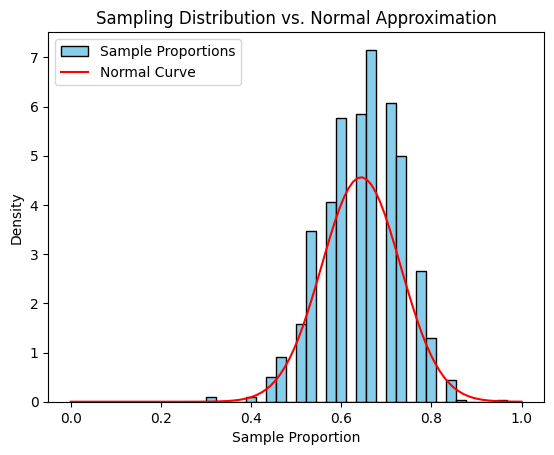

In [16]:
# Plot the histogram and normal curve
x = np.linspace(0, 1, 100)
normal_curve = norm.pdf(x, mean, std_error)

plt.hist(sample_proportions, bins=30, density=True, color='skyblue', edgecolor='black', label='Sample Proportions')
plt.plot(x, normal_curve, color='red', label='Normal Curve')
plt.title('Sampling Distribution vs. Normal Approximation')
plt.xlabel('Sample Proportion')
plt.ylabel('Density')
plt.legend()
plt.show()

**Observations**
1. The histogram of sample proportions becomes bell-shaped and closely resembles the theoretical normal curve as the number of samples increases.
2. The mean of the sampling distribution aligns closely with the true proportion p = 0.644.
3. The spread of the distribution matches the calculated standard error $\sigma_{\hat{p}}$.
4. The key takeaway is that regardless of the original population distribution, the sampling distribution of sample proportions approaches a normal distribution when the sample size is sufficiently large.